# 02 - EDA of all 97 features

We put all five feature groups in one notebook, so that we read every feature the same way.

**How we read every feature**

1. Categorical feature: crosstab against `target_3class`, then row percentages, compared with the reference line.
2. Numeric feature: median in each class, compared with the median of all parents.
3. We check every strong result **inside each division**, because the answers differ a lot between divisions.

What we found, and the rules that follow for the models, are written in `docs/dataset_guide.md`.

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/hpv_clean.csv")
CLASSES = ["Will vaccinate", "Only if free", "Undecided or no"]
reference = (df["target_3class"].value_counts(normalize=True) * 100).round(1)[CLASSES]
NUMERIC = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
MIN_ROW = 30   # a row with fewer parents is not ranked

print(df.shape)
reference

(2147, 101)


target_3class
Will vaccinate     70.3
Only if free       16.5
Undecided or no    13.2
Name: proportion, dtype: float64

In [2]:
GROUPS = {
    "A. The parent and the family": ["parent", "age", "marital_status", "religion", "residence", "education_years",
        "educ_spouse", "occupation", "occup_spouse", "hcw", "income", "family_member", "children_0", "daugther_0",
        "daughter_study", "ins_type", "ins_location", "religion_imp", "routine_health", "epi",
        "daughter_age_youngest", "daughter_age_oldest"],
    "B. HPV and the HPV vaccine: heard of it, and from where": ["hpv_heard", "hpv_hcw", "hpv_training", "hpv_friend",
        "hpv_relatives", "hpv_school", "hpv_pharmacy", "hpv_advert", "hpv_social", "hpv_mass",
        "vac_hear", "vac_hcw", "vac_train", "vac_friend", "vac_relative", "vac_school", "vac_pharmacy",
        "vac_advert", "vac_social", "vac_mass"],
    "C. Cervical cancer and its vaccine: heard of it, and from where": ["cancer_hear", "cancer_hcw", "cancer_training",
        "cancer_friend", "cancer_relative", "cancer_school", "cancer_pharmacy", "cancer_advert", "cancer_social",
        "cancer_mass", "canvac_hear", "canvac_hcw", "canvac_training", "canvac_friends", "canvac_relative",
        "canvac_school", "canvac_pharmacy", "canvac_advert", "canvac_social", "canvac_mass"],
    "D. Other knowledge, and cues to action": ["cancer_female", "pap_detect", "pap_done", "hpv_cervical", "hpv_transmit",
        "hpv_sexual", "hpv_blood", "hpv_pubtoilet", "hpv_mtc", "vac_reduce_risk", "recom_age",
        "cu1", "cu2", "cu3", "cu4"],
    "E. Beliefs": ["vul1", "vul2", "vul3", "vul4", "vul5", "sev1", "sev2", "sev3", "sev4", "sev5",
        "ben1", "ben2", "ben3", "ben4", "ben5", "bar1", "bar2", "bar3", "bar4", "bar5"],
}
features = [c for c in df.columns if not c.startswith(("target_", "meta_"))]
assert sorted(sum(GROUPS.values(), [])) == sorted(features)   # every feature is in exactly one group
{name: len(cols) for name, cols in GROUPS.items()}

{'A. The parent and the family': 22,
 'B. HPV and the HPV vaccine: heard of it, and from where': 20,
 'C. Cervical cancer and its vaccine: heard of it, and from where': 20,
 'D. Other knowledge, and cues to action': 15,
 'E. Beliefs': 20}

## 1. The functions used for every group

In [3]:
def table(col):
    """Row percentages of one categorical feature, with the row size and the reference line."""
    counts = pd.crosstab(df[col], df["target_3class"])[CLASSES]
    pct = (counts.div(counts.sum(axis=1), axis=0) * 100).round(1)
    pct.insert(0, "parents", counts.sum(axis=1))
    pct.loc["ALL PARENTS"] = [len(df)] + list(reference)
    return pct


def ranking(cols):
    """For each categorical feature: its row with the largest gap from the reference line."""
    rows = []
    for col in cols:
        if col in NUMERIC:
            continue
        counts = pd.crosstab(df[col], df["target_3class"])[CLASSES]
        pct = counts.div(counts.sum(axis=1), axis=0) * 100
        for answer in counts.index:
            n = int(counts.loc[answer].sum())
            if n < MIN_ROW:
                continue
            gaps = pct.loc[answer] - reference
            biggest = gaps.abs().idxmax()
            rows.append({"feature": col, "answer": answer, "parents": n, "class": biggest,
                         "share": round(pct.loc[answer, biggest], 1), "reference": reference[biggest],
                         "gap": round(gaps[biggest], 1)})
    out = pd.DataFrame(rows)
    out["abs"] = out["gap"].abs()
    return out.sort_values("abs", ascending=False).drop_duplicates("feature").drop(columns="abs").reset_index(drop=True)


def numeric_summary(cols):
    """Median of each numeric feature in each class, and for all parents."""
    cols = [c for c in cols if c in NUMERIC]
    out = df.groupby("target_3class")[cols].median().T[CLASSES]
    out["ALL PARENTS"] = df[cols].median()
    out["missing"] = df[cols].isna().sum()
    out["min"] = df[cols].min()
    out["max"] = df[cols].max()
    return out


def inside_divisions(col, answer, cls, min_parents=15):
    """Share of class `cls` among parents with this answer, and among the others, inside each division."""
    rows = []
    for division, g in df.groupby("meta_division"):
        a, b = g[g[col] == answer], g[g[col] != answer]
        if len(a) >= min_parents:
            rows.append({"division": division, "parents with this answer": len(a),
                         "share with this answer": round((a["target_3class"] == cls).mean() * 100),
                         "share of the others": round((b["target_3class"] == cls).mean() * 100)})
    out = pd.DataFrame(rows)
    out["difference"] = out["share with this answer"] - out["share of the others"]
    return out

## Group A. The parent and the family

In [4]:
cols = GROUPS["A. The parent and the family"]
ranking(cols)

,feature,answer,parents,class,share,reference,gap
0,epi,Unsure,100,Will vaccinate,26.0,70.3,-44.3
1,occupation,Agriculture,30,Will vaccinate,33.3,70.3,-37.0
2,hcw,Yes,183,Will vaccinate,98.4,70.3,28.1
3,ins_type,Madrasha,209,Will vaccinate,44.0,70.3,-26.3
4,occup_spouse,Others,143,Will vaccinate,49.7,70.3,-20.6
5,marital_status,Living without a spouse,76,Will vaccinate,51.3,70.3,-19.0
6,routine_health,Less than 1year interval,668,Will vaccinate,83.2,70.3,12.9
7,religion_imp,Rather important,309,Undecided or no,25.2,13.2,12.0
8,religion,Hindu,337,Only if free,8.0,16.5,-8.5
9,ins_location,Rural,690,Only if free,24.6,16.5,8.1


### The nine numeric features

In [5]:
numeric_summary(cols)

target_3class,Will vaccinate,Only if free,Undecided or no,ALL PARENTS,missing,min,max
age,37.0,37.0,40.0,38.0,0,24.0,58.0
education_years,12.0,10.0,10.0,12.0,2,0.0,23.0
educ_spouse,12.0,10.0,12.0,12.0,126,0.0,21.0
income,39000.0,25000.0,40000.0,35000.0,3,5000.0,1000000.0
family_member,5.0,5.0,5.0,5.0,1,2.0,17.0
children_0,2.0,2.0,2.0,2.0,0,1.0,9.0
daugther_0,1.0,1.0,1.0,1.0,0,1.0,6.0
daughter_age_youngest,11.0,11.0,11.0,11.0,9,0.0,28.0
daughter_age_oldest,13.0,12.0,12.0,13.0,9,1.0,32.0


### Full tables for the features at the top of the ranking

In [6]:
for col in ["epi", "occupation", "hcw", "ins_type", "occup_spouse", "marital_status", "routine_health", "religion_imp", "residence", "parent"]:
    print(col)
    display(table(col))

epi


target_3class,parents,Will vaccinate,Only if free,Undecided or no
epi,,,,
All,1527,71.2,18.6,10.2
No,28,75.0,21.4,3.6
Some,492,76.2,8.9,14.8
Unsure,100,26.0,20.0,54.0
ALL PARENTS,2147,70.3,16.5,13.2


occupation


target_3class,parents,Will vaccinate,Only if free,Undecided or no
occupation,,,,
Agriculture,30,33.3,46.7,20.0
Business Person,186,51.1,19.4,29.6
Government Job,137,93.4,2.9,3.6
Housewife,1360,67.6,18.7,13.8
Others,57,57.9,28.1,14.0
Private Job,374,85.8,8.0,6.1
Student,3,100.0,0.0,0.0
ALL PARENTS,2147,70.3,16.5,13.2


hcw


target_3class,parents,Will vaccinate,Only if free,Undecided or no
hcw,,,,
No,1964,67.7,17.9,14.5
Yes,183,98.4,1.6,0.0
ALL PARENTS,2147,70.3,16.5,13.2


... (10 outputs left out)

residence


target_3class,parents,Will vaccinate,Only if free,Undecided or no
residence,,,,
Rural,783,64.6,24.0,11.4
Semi-urban,258,74.8,14.3,10.9
Urban,1106,73.2,11.7,15.1
ALL PARENTS,2147,70.3,16.5,13.2


parent


target_3class,parents,Will vaccinate,Only if free,Undecided or no
parent,,,,
Father,400,62.5,18.2,19.2
Mother,1747,72.1,16.1,11.8
ALL PARENTS,2147,70.3,16.5,13.2


## Group B. HPV and the HPV vaccine: heard of it, and from where

In [7]:
cols = GROUPS["B. HPV and the HPV vaccine: heard of it, and from where"]
ranking(cols)

,feature,answer,parents,class,share,reference,gap
0,hpv_training,Yes,93,Will vaccinate,97.8,70.3,27.5
1,vac_train,Yes,87,Will vaccinate,97.7,70.3,27.4
2,hpv_pharmacy,Yes,33,Will vaccinate,97.0,70.3,26.7
3,vac_hcw,Yes,358,Will vaccinate,95.8,70.3,25.5
4,vac_advert,Yes,65,Will vaccinate,95.4,70.3,25.1
5,hpv_social,Yes,185,Will vaccinate,95.1,70.3,24.8
6,hpv_hcw,Yes,365,Will vaccinate,94.8,70.3,24.5
7,hpv_heard,Yes,485,Will vaccinate,94.0,70.3,23.7
8,vac_hear,Yes,480,Will vaccinate,94.0,70.3,23.7
9,vac_pharmacy,Yes,47,Will vaccinate,93.6,70.3,23.3


### `hpv_heard` and `vac_hear` are almost the same column

The 18 "from where" columns were only asked after a Yes to one of these two.

In [8]:
display(table("hpv_heard"))
display(pd.crosstab(df["hpv_heard"], df["vac_hear"]))

target_3class,parents,Will vaccinate,Only if free,Undecided or no
hpv_heard,,,,
No,1662,63.4,20.3,16.4
Yes,485,94.0,3.5,2.5
ALL PARENTS,2147,70.3,16.5,13.2


vac_hear,No,Yes
hpv_heard,,
No,1627,35
Yes,40,445


## Group C. Cervical cancer and its vaccine: heard of it, and from where

In [9]:
cols = GROUPS["C. Cervical cancer and its vaccine: heard of it, and from where"]
ranking(cols)

,feature,answer,parents,class,share,reference,gap
0,cancer_hear,No,426,Will vaccinate,42.3,70.3,-28.0
1,cancer_training,Yes,114,Will vaccinate,93.9,70.3,23.6
2,canvac_social,Yes,449,Will vaccinate,92.9,70.3,22.6
3,canvac_hcw,Yes,714,Will vaccinate,92.3,70.3,22.0
4,canvac_training,Yes,106,Will vaccinate,91.5,70.3,21.2
5,canvac_hear,Yes,1045,Will vaccinate,89.8,70.3,19.5
6,cancer_social,Yes,530,Will vaccinate,88.9,70.3,18.6
7,canvac_mass,Yes,474,Will vaccinate,86.9,70.3,16.6
8,cancer_school,Yes,120,Will vaccinate,86.7,70.3,16.4
9,canvac_relative,Yes,268,Will vaccinate,85.8,70.3,15.5


In [10]:
display(table("cancer_hear"))
display(table("canvac_hear"))
display(pd.crosstab(df["cancer_hear"], df["canvac_hear"]))

target_3class,parents,Will vaccinate,Only if free,Undecided or no
cancer_hear,,,,
No,426,42.3,17.4,40.4
Yes,1721,77.2,16.3,6.5
ALL PARENTS,2147,70.3,16.5,13.2


target_3class,parents,Will vaccinate,Only if free,Undecided or no
canvac_hear,,,,
No,1102,51.8,26.5,21.7
Yes,1045,89.8,5.9,4.3
ALL PARENTS,2147,70.3,16.5,13.2


canvac_hear,No,Yes
cancer_hear,,
No,415,11
Yes,687,1034


## Group D. Other knowledge, and cues to action

### The 15 questions of group D

| Feature | Question in the survey |
|---|---|
| `cancer_female` | Does cervical cancer only occur in females? |
| `pap_detect` | Do you know that getting a Pap smear test helps early detection of cervical cancer? |
| `pap_done` | Have you (or your wife) ever done a Pap smear test? |
| `hpv_cervical` | Do you know that HPV is the main cause of cervical cancer? |
| `hpv_transmit` | Do you know how HPV is transmitted from one person to another? |
| `hpv_sexual` | Transmission mode: sexual transmission |
| `hpv_blood` | Transmission mode: blood transfusion |
| `hpv_pubtoilet` | Transmission mode: use of a public toilet |
| `hpv_mtc` | Transmission mode: during pregnancy (mother to child) |
| `vac_reduce_risk` | Do you know that HPV vaccination can reduce cervical cancer risk? |
| `recom_age` | What is the recommended age for the HPV vaccine? |
| `cu1` | Do you have a personal history of cancer? |
| `cu2` | Do any of your friends or family members have a history of cancer? |
| `cu3` | Do you have a personal history of cervical cancer? |
| `cu4` | Do any of your friends or family members have a history of cervical cancer? |


In [11]:
cols = GROUPS["D. Other knowledge, and cues to action"]
ranking(cols)

,feature,answer,parents,class,share,reference,gap
0,cancer_female,No,322,Will vaccinate,33.5,70.3,-36.8
1,hpv_transmit,Yes,378,Will vaccinate,97.4,70.3,27.1
2,hpv_cervical,Yes,375,Will vaccinate,97.3,70.3,27.0
3,hpv_sexual,Yes,368,Will vaccinate,97.3,70.3,27.0
4,hpv_mtc,Yes,124,Will vaccinate,95.2,70.3,24.9
5,pap_detect,Yes,714,Will vaccinate,94.8,70.3,24.5
6,recom_age,9-13 years,355,Will vaccinate,94.4,70.3,24.1
7,pap_done,Yes,302,Will vaccinate,93.7,70.3,23.4
8,hpv_blood,Yes,85,Will vaccinate,92.9,70.3,22.6
9,vac_reduce_risk,Yes,1012,Will vaccinate,87.6,70.3,17.3


In [12]:
for col in ["cancer_female", "hpv_transmit", "pap_detect", "vac_reduce_risk", "recom_age"]:
    print(col)
    display(table(col))
display(pd.crosstab(df["hpv_transmit"], df["hpv_sexual"]))

cancer_female


target_3class,parents,Will vaccinate,Only if free,Undecided or no
cancer_female,,,,
No,322,33.5,18.9,47.5
Yes,1825,76.8,16.1,7.2
ALL PARENTS,2147,70.3,16.5,13.2


hpv_transmit


target_3class,parents,Will vaccinate,Only if free,Undecided or no
hpv_transmit,,,,
No,1769,64.5,19.6,15.9
Yes,378,97.4,1.9,0.8
ALL PARENTS,2147,70.3,16.5,13.2


pap_detect


target_3class,parents,Will vaccinate,Only if free,Undecided or no
pap_detect,,,,
No,1433,58.1,23.2,18.7
Yes,714,94.8,2.9,2.2
ALL PARENTS,2147,70.3,16.5,13.2


vac_reduce_risk


target_3class,parents,Will vaccinate,Only if free,Undecided or no
vac_reduce_risk,,,,
No,1135,54.8,23.3,21.9
Yes,1012,87.6,8.9,3.5
ALL PARENTS,2147,70.3,16.5,13.2


recom_age


target_3class,parents,Will vaccinate,Only if free,Undecided or no
recom_age,,,,
13-15 years,212,85.4,11.8,2.8
7-9 years,36,83.3,13.9,2.8
9-13 years,355,94.4,4.8,0.8
Don't Know,1544,62.4,19.9,17.7
ALL PARENTS,2147,70.3,16.5,13.2


hpv_sexual,No,Yes
hpv_transmit,,
No,1769,0
Yes,10,368


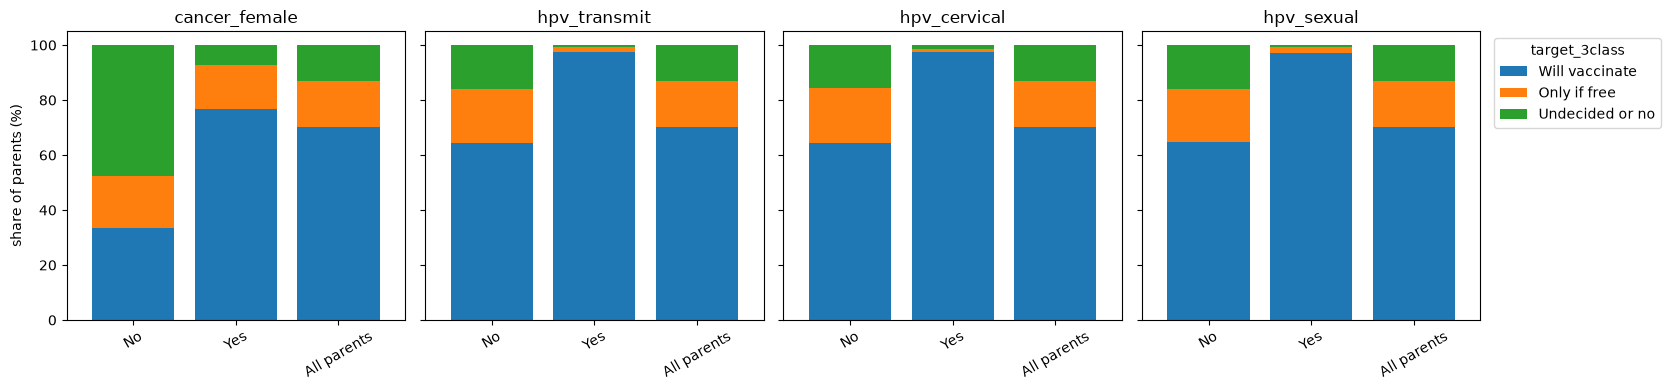

In [13]:
top = ranking(GROUPS["D. Other knowledge, and cues to action"])["feature"].head(4).tolist()

fig, axes = plt.subplots(1, len(top), figsize=(4.2 * len(top), 4), sharey=True)
for ax, col in zip(axes, top):
    pct = (pd.crosstab(df[col], df["target_3class"], normalize="index") * 100)[CLASSES]
    pct.loc["All parents"] = reference
    pct.plot(kind="bar", stacked=True, ax=ax, legend=False, width=0.8)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("share of parents (%)")
    ax.tick_params(axis="x", rotation=30)
axes[-1].legend(title="target_3class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Our findings for group D

1. Of the 322 parents who answered "No" to "Does cervical cancer only occur in females?", 47.5% are in the class "Undecided or no". Among all parents it is 13.2%.

   This difference comes from two divisions:

   | Division | Parents who answered "No" | Of them, in "Undecided or no" | Parents who answered "Yes" | Of them, in "Undecided or no" |
   |---|---|---|---|---|
   | Dhaka | 131 | 106 (81%) | 429 | 36 (8%) |
   | Chattogram | 67 | 38 (57%) | 366 | 47 (13%) |

   In Khulna, Rajshahi, Sylhet and Barishal the two groups do not differ.

2. Of the 378 parents who answered "Yes" to "Do you know how HPV is transmitted?", 97.4% are in the class "Will vaccinate". Among all parents it is 70.3%. `hpv_cervical` and `hpv_sexual` show the same result, because they are answered Yes by nearly the same parents. We count this as one finding.

3. Of the 714 parents who answered "Yes" to "Do you know that a Pap smear test helps early detection of cervical cancer?", 94.8% are in the class "Will vaccinate". Among all parents it is 70.3%.


### What we found strange in group D

1. **Two columns that are almost one.** 1,769 parents answered "No" to "Do you know how HPV is transmitted?", so they were not asked "what is the primary transmission mode?". In the clean file those skipped answers are "No". Only 10 parents answered Yes to the first question and No to "sexual transmission", and 368 answered Yes to both. So `hpv_transmit` and `hpv_sexual` are almost the same column: they differ for only 10 of 2,147 parents. They should be read as one finding, not two. The same holds for `hpv_blood`, `hpv_pubtoilet` and `hpv_mtc`, which were also asked only after a Yes to `hpv_transmit`.

2. **Rows that are too small.** The percentages for `cu1`, `cu3` and `hpv_pubtoilet` cannot be trusted. Only 33, 32 and 26 parents answered Yes to them, and with so few parents a handful of different answers would change the percentage a lot.

3. **The interviewer explains before asking.** Just above the question for `vac_reduce_risk`, the form tells the interviewer to explain to the parent that HPV vaccination and cervical cancer vaccination are the same. The question "Will you give your daughter the HPV vaccine?" comes after that. So a parent's answer may depend on how the interviewer explained it. Different areas had different interviewers, and we cannot check from the data how each of them explained it.


## Group E. Beliefs

In [14]:
cols = GROUPS["E. Beliefs"]
ranking(cols)

,feature,answer,parents,class,share,reference,gap
0,vul2,Disagree,41,Only if free,61.0,16.5,44.5
1,bar2,Agree,219,Will vaccinate,33.8,70.3,-36.5
2,sev2,Disagree,42,Only if free,52.4,16.5,35.9
3,bar1,Neutral,390,Will vaccinate,35.4,70.3,-34.9
4,ben1,Neutral,478,Will vaccinate,36.6,70.3,-33.7
5,ben5,Disagree,31,Only if free,48.4,16.5,31.9
6,bar3,Neutral,577,Will vaccinate,40.0,70.3,-30.3
7,bar4,Strongly disagree,62,Will vaccinate,98.4,70.3,28.1
8,bar5,Neutral,720,Will vaccinate,43.8,70.3,-26.6
9,vul1,Strongly agree,103,Will vaccinate,95.1,70.3,24.8


### The statements behind the 20 belief features

| Block | Statements, in order 1 to 5 |
|---|---|
| `vul` (vulnerability) | HPV can cause sexually transmitted disease / HPV can cause genital warts / There is a risk for young women to contract HPV / HPV infection is a serious health concern / I worry that my child might get HPV |
| `sev` (severity) | People with HPV might not have symptoms / HPV-associated warts could be uncomfortable or itchy / HPV-associated wart is a serious condition / HPV-associated cervical cancer is a serious condition / It can occur in middle age |
| `ben` (benefits) | I trust vaccinations / The vaccine is effective against genital warts / The vaccine is effective against cervical cancer / Vaccinated girls are less likely to get HPV / Vaccination increases awareness of STDs |
| `bar` (barriers) | **I shall not vaccinate my daughter** as it is painful / **I shall not vaccinate my daughter** as it can cause an adverse effect / **I shall not vaccinate my daughter** as it needs two injections / The vaccine is so new that I want to wait before deciding / **I shall vaccinate my daughter even if it is not free** |

The five barrier statements contain the decision itself. See `docs/dataset_guide.md`, section 5.5.

In [15]:
for col in ["bar1", "bar2", "bar3", "bar4", "bar5"]:
    print(col)
    display(table(col))

bar1


target_3class,parents,Will vaccinate,Only if free,Undecided or no
bar1,,,,
Agree,79,41.8,29.1,29.1
Disagree,1449,78.0,15.7,6.3
Neutral,390,35.4,22.8,41.8
Strongly agree,3,100.0,0.0,0.0
Strongly disagree,226,90.7,6.2,3.1
ALL PARENTS,2147,70.3,16.5,13.2


bar2


target_3class,parents,Will vaccinate,Only if free,Undecided or no
bar2,,,,
Agree,219,33.8,37.9,28.3
Disagree,1177,86.3,11.0,2.7
Neutral,598,46.5,22.7,30.8
Strongly agree,13,38.5,15.4,46.2
Strongly disagree,140,97.1,2.9,0.0
ALL PARENTS,2147,70.3,16.5,13.2


bar3


target_3class,parents,Will vaccinate,Only if free,Undecided or no
bar3,,,,
Agree,89,57.3,25.8,16.9
Disagree,1294,81.2,13.5,5.3
Neutral,577,40.0,25.3,34.7
Strongly agree,4,75.0,25.0,0.0
Strongly disagree,183,94.5,4.9,0.5
ALL PARENTS,2147,70.3,16.5,13.2


bar4


target_3class,parents,Will vaccinate,Only if free,Undecided or no
bar4,,,,
Agree,793,64.3,24.6,11.1
Disagree,536,93.1,4.9,2.1
Neutral,670,57.5,17.8,24.8
Strongly agree,86,62.8,15.1,22.1
Strongly disagree,62,98.4,1.6,0.0
ALL PARENTS,2147,70.3,16.5,13.2


bar5


target_3class,parents,Will vaccinate,Only if free,Undecided or no
bar5,,,,
Agree,704,90.1,6.2,3.7
Disagree,554,76.7,15.5,7.8
Neutral,720,43.8,28.5,27.8
Strongly agree,100,89.0,5.0,6.0
Strongly disagree,69,66.7,20.3,13.0
ALL PARENTS,2147,70.3,16.5,13.2


### "Neutral" means something different for parents who never heard of HPV

In [16]:
beliefs = GROUPS["E. Beliefs"]
neutral = pd.DataFrame({col: (df[col] == "Neutral").groupby(df["hpv_heard"]).mean() * 100 for col in beliefs}).T.round(0)
neutral.columns = ["never heard of HPV: % Neutral", "heard of HPV: % Neutral"]
print("Parents with the same answer to all 20 statements:", int((df[beliefs].nunique(axis=1) == 1).sum()))
neutral

Parents with the same answer to all 20 statements: 166


,never heard of HPV: % Neutral,heard of HPV: % Neutral
vul1,67.0,13.0
vul2,79.0,22.0
vul3,66.0,20.0
vul4,48.0,15.0
vul5,47.0,16.0
sev1,82.0,22.0
sev2,73.0,19.0
sev3,66.0,28.0
sev4,34.0,15.0
sev5,51.0,18.0


## 6. Do the strong results hold inside each division?

A result that appears in only one or two divisions may come from how the interviewers there asked or recorded the answers.

In [17]:
checks = [("cancer_female", "No", "Undecided or no"),
          ("cancer_hear", "No", "Will vaccinate"),
          ("hpv_heard", "Yes", "Will vaccinate"),
          ("pap_detect", "Yes", "Will vaccinate"),
          ("hcw", "Yes", "Will vaccinate"),
          ("ins_type", "Madrasha", "Will vaccinate"),
          ("epi", "Unsure", "Undecided or no"),
          ("religion_imp", "Rather important", "Undecided or no")]
for col, answer, cls in checks:
    print(f'{col} = "{answer}"  ->  share of "{cls}"')
    display(inside_divisions(col, answer, cls))

cancer_female = "No"  ->  share of "Undecided or no"


,division,parents with this answer,share with this answer,share of the others,difference
0,Barishal,21,19,15,4
1,Chattogram,67,57,13,44
2,Dhaka,131,81,8,73
3,Khulna,46,2,6,-4
4,Rajshahi,22,5,5,0
5,Sylhet,29,10,5,5


cancer_hear = "No"  ->  share of "Will vaccinate"


,division,parents with this answer,share with this answer,share of the others,difference
0,Barishal,32,69,69,0
1,Chattogram,63,8,55,-47
2,Dhaka,137,8,81,-73
3,Khulna,27,67,81,-14
4,Rajshahi,38,26,68,-42
5,Rangpur,59,97,98,-1
6,Sylhet,62,79,100,-21


hpv_heard = "Yes"  ->  share of "Will vaccinate"


,division,parents with this answer,share with this answer,share of the others,difference
0,Barishal,49,69,69,0
1,Chattogram,42,95,43,52
2,Dhaka,163,99,48,51
3,Khulna,86,91,73,18
4,Mymensingh,99,99,98,1
5,Rajshahi,29,93,58,35
6,Rangpur,15,100,97,3


... (6 outputs left out)

epi = "Unsure"  ->  share of "Undecided or no"


,division,parents with this answer,share with this answer,share of the others,difference
0,Dhaka,71,69,19,50


religion_imp = "Rather important"  ->  share of "Undecided or no"


,division,parents with this answer,share with this answer,share of the others,difference
0,Dhaka,216,32,21,11
1,Khulna,48,8,4,4
2,Rajshahi,21,0,6,-6


### Where the parents with these answers were interviewed

In [18]:
rows = {}
for col, answer in [("epi", "Unsure"), ("religion_imp", "Rather important"), ("cancer_female", "No"),
                    ("ins_type", "Madrasha"), ("occup_spouse", "Others"), ("hcw", "Yes")]:
    rows[f"{col} = {answer}"] = df.loc[df[col] == answer, "meta_division"].value_counts()
pd.DataFrame(rows).T.fillna(0).astype(int)

meta_division,Barishal,Chattogram,Dhaka,Khulna,Mymensingh,Rajshahi,Rangpur,Sylhet
epi = Unsure,6,4,71,14,1,4,0,0
religion_imp = Rather important,2,8,216,48,3,21,8,3
cancer_female = No,21,67,131,46,0,22,6,29
ins_type = Madrasha,2,106,12,15,33,19,19,3
occup_spouse = Others,6,77,1,31,1,26,1,0
hcw = Yes,7,37,100,16,3,11,7,2


### The missing values of `educ_spouse` are not spread evenly

In [19]:
pd.crosstab(df["meta_division"], df["educ_spouse"].isna()).rename(columns={False: "has a value", True: "missing"})

educ_spouse,has a value,missing
meta_division,,
Barishal,127,0
Chattogram,433,0
Dhaka,544,16
Khulna,231,0
Mymensingh,160,0
Rajshahi,156,109
Rangpur,227,1
Sylhet,143,0


## 7. The class distribution in each division

In [20]:
by_div = (pd.crosstab(df["meta_division"], df["target_3class"], normalize="index") * 100).round(1)[CLASSES]
by_div.insert(0, "parents", df["meta_division"].value_counts())
by_div.sort_values("Will vaccinate")

target_3class,parents,Will vaccinate,Only if free,Undecided or no
meta_division,,,,
Chattogram,433,48.3,32.1,19.6
Rajshahi,265,62.3,32.5,5.3
Dhaka,560,63.0,11.6,25.4
Barishal,127,69.3,15.0,15.7
Khulna,231,79.7,15.2,5.2
Sylhet,143,90.9,2.8,6.3
Rangpur,228,97.4,2.2,0.4
Mymensingh,160,98.8,0.6,0.6


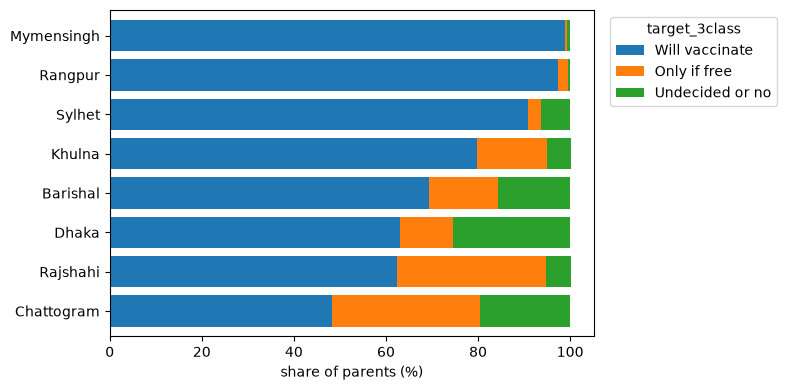

In [21]:
ax = by_div.sort_values("Will vaccinate")[CLASSES].plot(kind="barh", stacked=True, figsize=(8, 4), width=0.8)
ax.set_xlabel("share of parents (%)")
ax.set_ylabel("")
ax.legend(title="target_3class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()